# Scenario 3 - Energy Management in a Smart Grid
### 43008 Reinforcement Learning - Assignment 1 (Spring 2026)

This notebook formulates the Energy Management in a Smart Grid case study as a finite-horizon MDP (T = 24) and solves it with Value Iteration (backward induction) and Policy Iteration. It then simulates the optimal policies and compares the two algorithms. The 24-hour day uses time-varying dynamics - a `NIGHT -> MORNING -> MIDDAY -> EVENING` generation/demand cycle plus a time-of-use import tariff - so the optimal policy is non-stationary. Full rationale for the model is in the report.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RNG_SEED = 42
np.random.seed(RNG_SEED)
np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
print("Environment ready. numpy", np.__version__)

Environment ready. numpy 2.0.2


## 1. MDP Formulation

Hourly decisions over a fixed 24-hour day → finite-horizon MDP with T = 24 (`t = 0…23`, day ends at `t = 24`). The state is fully observed; action effects are stochastic. The full rationale for every state, action, reward and transition value is in the report (§2, MDP Formulation) — this notebook keeps only what is needed to follow the code.

### 1.1 States (S = 10) — factored
`SITUATION` ∈ {SURPLUS, BALANCED, DEFICIT} × `BATTERY` ∈ {LOW, MED, HIGH} → 9 states, written `SITUATION|BATTERY`, plus `CRITICAL` (a deficit left uncovered — blackout risk, large penalty until the grid recovers).

### 1.2 Actions (A = 6)
`DISTRIBUTE`, `CHARGE`, `DISCHARGE`, `LOAD_SHED`, `HOLD`, `IMPORT_GRID` (buy from the neighbouring grid — costs money, far more at the evening peak; an “imagination to complement” addition, justified in the report).

### 1.3 Reward  `R_t(s, a) = situation_value(s) + action_effect(s, a) + tariff_t(a)`
`situation_value`: BALANCED +8, SURPLUS +4, DEFICIT −2, CRITICAL −30. `action_effect` folds each action's cost and service outcome into one state-dependent figure. `tariff_t` applies only to `IMPORT_GRID` (time-of-use: NIGHT −2.5 / MORNING −4 / MIDDAY −3 / EVENING −11). Terminal value `V_T(s) = situation_value(s) + 1.5·battery`.

### 1.4 Transitions — time-varying `P_t`
A hand-designed phase-neutral base `P_base(s'|s, a)` (the situation as a mean-reverting chain; the battery level moving with the action; an uncovered deficit carrying a blackout risk to `CRITICAL`, larger at low battery), reweighted each phase by a `supply_bias` (NIGHT −0.55 / MORNING +0.35 / MIDDAY +1.9 / EVENING −2.3) that tilts the next situation toward SURPLUS or DEFICIT. Every `P_t(·|s, a)` row is renormalised to 1. Values and derivation: report §2.

In [2]:
SITS = ["SURPLUS", "BALANCED", "DEFICIT"]
BATS = ["LOW", "MED", "HIGH"]
STATES  = [f"{s}|{b}" for s in SITS for b in BATS] + ["CRITICAL"]
ACTIONS = ["DISTRIBUTE", "CHARGE", "DISCHARGE", "LOAD_SHED", "HOLD", "IMPORT_GRID"]
S, A = len(STATES), len(ACTIONS)
HORIZON = 24
CRIT = S - 1                                            # index of the CRITICAL state

s_idx = {name: i for i, name in enumerate(STATES)}
a_idx = {name: i for i, name in enumerate(ACTIONS)}
def decode(state):              return state // 3, state % 3    # state -> (situation, battery)
def encode(situation, battery): return situation * 3 + battery

PHASES = ["NIGHT", "MORNING", "MIDDAY", "EVENING"]
def phase_of(t): return PHASES[min(t // 6, 3)]          # 6 hours per phase
SUPPLY_BIAS   = {"NIGHT": -0.55, "MORNING": 0.35, "MIDDAY": 1.90, "EVENING": -2.30}
IMPORT_TARIFF = {"NIGHT": -2.5,  "MORNING": -4.0, "MIDDAY": -3.0, "EVENING": -11.0}

print(f"S = {S} states, A = {A} actions, finite horizon T = {HORIZON}")

S = 10 states, A = 6 actions, finite horizon T = 24


In [3]:
# ---- Reward model --------------------------------------------------------------
SITUATION_VALUE = {0: 4.0, 1: 8.0, 2: -2.0}             # SURPLUS, BALANCED, DEFICIT

def reward(s, a, import_cost):
    """R_t(s, a) = situation value + action effect + (time-of-use tariff, IMPORT_GRID only)."""
    name = ACTIONS[a]
    if s == CRIT:
        if name == "IMPORT_GRID":
            return -30.0 + (10.0 + import_cost)
        return -30.0 + {"LOAD_SHED": 8.0, "DISCHARGE": 5.0,
                        "DISTRIBUTE": 0.0, "HOLD": 0.0, "CHARGE": -4.0}[name]
    situation, battery = decode(s)
    r = SITUATION_VALUE[situation]
    if name == "DISTRIBUTE":
        r += 2.0 if situation in (0, 1) else 0.0
    elif name == "CHARGE":
        r += {0: 1.0, 1: -1.0, 2: -6.0}[situation]
        if battery == 2:
            r -= 3.0
    elif name == "DISCHARGE":
        if battery == 0:
            r -= 8.0
        elif situation == 2:
            r += 6.0
        else:
            r -= 3.0
    elif name == "LOAD_SHED":
        r -= 7.0
        if situation in (0, 1):
            r -= 3.0
    elif name == "IMPORT_GRID":
        r += import_cost
        if situation in (0, 1) and battery == 2:
            r -= 3.0
    return r

R_time = np.array([[[reward(s, a, IMPORT_TARIFF[phase_of(t)]) for a in range(A)]
                    for s in range(S)] for t in range(HORIZON)])              # (T, S, A)
terminal_value = np.array([-30.0 if s == CRIT
                           else SITUATION_VALUE[decode(s)[0]] + 1.5 * decode(s)[1]
                           for s in range(S)], dtype=float)

assert np.isfinite(R_time).all()
print("Reward matrix R_t(s, a) at MIDDAY (t=12):")
print(pd.DataFrame(R_time[12], index=STATES, columns=ACTIONS).round(1))
print("\nReward matrix R_t(s, a) at EVENING (t=18) - note the IMPORT_GRID column:")
print(pd.DataFrame(R_time[18], index=STATES, columns=ACTIONS).round(1))

Reward matrix R_t(s, a) at MIDDAY (t=12):
               DISTRIBUTE  CHARGE  DISCHARGE  LOAD_SHED  HOLD  IMPORT_GRID
SURPLUS|LOW           6.0     5.0       -4.0       -6.0   4.0          1.0
SURPLUS|MED           6.0     5.0        1.0       -6.0   4.0          1.0
SURPLUS|HIGH          6.0     2.0        1.0       -6.0   4.0         -2.0
BALANCED|LOW         10.0     7.0        0.0       -2.0   8.0          5.0
BALANCED|MED         10.0     7.0        5.0       -2.0   8.0          5.0
BALANCED|HIGH        10.0     4.0        5.0       -2.0   8.0          2.0
DEFICIT|LOW          -2.0    -8.0      -10.0       -9.0  -2.0         -5.0
DEFICIT|MED          -2.0    -8.0        4.0       -9.0  -2.0         -5.0
DEFICIT|HIGH         -2.0   -11.0        4.0       -9.0  -2.0         -5.0
CRITICAL            -30.0   -34.0      -25.0      -22.0 -30.0        -23.0

Reward matrix R_t(s, a) at EVENING (t=18) - note the IMPORT_GRID column:
               DISTRIBUTE  CHARGE  DISCHARGE  LOAD_SHED  HO

In [4]:
# ---- Base (phase-neutral) transition model  P_base  ---------------------------
# BASE_SPEC[(state, action)] = { next_state: relative weight, ... }; rows renormalised to 1.
BASE_SPEC = {
    # DISTRIBUTE
    ("SURPLUS|LOW", "DISTRIBUTE"): {"SURPLUS|LOW": 0.45, "BALANCED|LOW": 0.45, "DEFICIT|LOW": 0.10},
    ("SURPLUS|MED", "DISTRIBUTE"): {"SURPLUS|MED": 0.40, "BALANCED|MED": 0.40, "DEFICIT|MED": 0.10, "SURPLUS|LOW": 0.05, "BALANCED|LOW": 0.05},
    ("SURPLUS|HIGH", "DISTRIBUTE"): {"SURPLUS|HIGH": 0.40, "BALANCED|HIGH": 0.40, "DEFICIT|HIGH": 0.10, "SURPLUS|MED": 0.05, "BALANCED|MED": 0.05},
    ("BALANCED|LOW", "DISTRIBUTE"): {"BALANCED|LOW": 0.50, "SURPLUS|LOW": 0.25, "DEFICIT|LOW": 0.25},
    ("BALANCED|MED", "DISTRIBUTE"): {"BALANCED|MED": 0.45, "SURPLUS|MED": 0.25, "DEFICIT|MED": 0.25, "BALANCED|LOW": 0.05},
    ("BALANCED|HIGH", "DISTRIBUTE"): {"BALANCED|HIGH": 0.45, "SURPLUS|HIGH": 0.25, "DEFICIT|HIGH": 0.25, "BALANCED|MED": 0.05},
    ("DEFICIT|LOW", "DISTRIBUTE"): {"CRITICAL": 0.55, "BALANCED|LOW": 0.20, "DEFICIT|LOW": 0.20, "SURPLUS|LOW": 0.05},
    ("DEFICIT|MED", "DISTRIBUTE"): {"BALANCED|MED": 0.40, "DEFICIT|MED": 0.35, "CRITICAL": 0.20, "SURPLUS|MED": 0.05},
    ("DEFICIT|HIGH", "DISTRIBUTE"): {"DEFICIT|HIGH": 0.40, "BALANCED|HIGH": 0.35, "SURPLUS|HIGH": 0.10, "BALANCED|MED": 0.05, "DEFICIT|MED": 0.05, "CRITICAL": 0.05},
    ("CRITICAL", "DISTRIBUTE"): {"CRITICAL": 0.90, "BALANCED|LOW": 0.05, "DEFICIT|LOW": 0.05},
    # CHARGE
    ("SURPLUS|LOW", "CHARGE"): {"SURPLUS|MED": 0.25, "BALANCED|MED": 0.25, "SURPLUS|LOW": 0.20, "BALANCED|LOW": 0.20, "DEFICIT|LOW": 0.05, "DEFICIT|MED": 0.05},
    ("SURPLUS|MED", "CHARGE"): {"SURPLUS|HIGH": 0.25, "BALANCED|HIGH": 0.25, "SURPLUS|MED": 0.20, "BALANCED|MED": 0.20, "DEFICIT|MED": 0.05, "DEFICIT|HIGH": 0.05},
    ("SURPLUS|HIGH", "CHARGE"): {"SURPLUS|HIGH": 0.45, "BALANCED|HIGH": 0.45, "DEFICIT|HIGH": 0.10},
    ("BALANCED|LOW", "CHARGE"): {"BALANCED|LOW": 0.45, "SURPLUS|LOW": 0.15, "BALANCED|MED": 0.15, "DEFICIT|LOW": 0.15, "SURPLUS|MED": 0.05, "DEFICIT|MED": 0.05},
    ("BALANCED|MED", "CHARGE"): {"BALANCED|MED": 0.45, "SURPLUS|MED": 0.15, "BALANCED|HIGH": 0.15, "DEFICIT|MED": 0.15, "SURPLUS|HIGH": 0.05, "DEFICIT|HIGH": 0.05},
    ("BALANCED|HIGH", "CHARGE"): {"BALANCED|HIGH": 0.50, "SURPLUS|HIGH": 0.25, "DEFICIT|HIGH": 0.25},
    ("DEFICIT|LOW", "CHARGE"): {"CRITICAL": 0.55, "BALANCED|LOW": 0.20, "DEFICIT|LOW": 0.20, "SURPLUS|LOW": 0.05},
    ("DEFICIT|MED", "CHARGE"): {"BALANCED|MED": 0.35, "DEFICIT|MED": 0.30, "CRITICAL": 0.20, "SURPLUS|MED": 0.05, "BALANCED|HIGH": 0.05, "DEFICIT|HIGH": 0.05},
    ("DEFICIT|HIGH", "CHARGE"): {"DEFICIT|HIGH": 0.45, "BALANCED|HIGH": 0.40, "SURPLUS|HIGH": 0.10, "CRITICAL": 0.05},
    ("CRITICAL", "CHARGE"): {"CRITICAL": 0.90, "BALANCED|LOW": 0.05, "DEFICIT|LOW": 0.05},
    # DISCHARGE
    ("SURPLUS|LOW", "DISCHARGE"): {"SURPLUS|LOW": 0.45, "BALANCED|LOW": 0.45, "DEFICIT|LOW": 0.10},
    ("SURPLUS|MED", "DISCHARGE"): {"SURPLUS|LOW": 0.40, "BALANCED|LOW": 0.40, "DEFICIT|LOW": 0.10, "SURPLUS|MED": 0.05, "BALANCED|MED": 0.05},
    ("SURPLUS|HIGH", "DISCHARGE"): {"SURPLUS|MED": 0.40, "BALANCED|MED": 0.40, "DEFICIT|MED": 0.10, "SURPLUS|HIGH": 0.05, "BALANCED|HIGH": 0.05},
    ("BALANCED|LOW", "DISCHARGE"): {"BALANCED|LOW": 0.50, "SURPLUS|LOW": 0.25, "DEFICIT|LOW": 0.25},
    ("BALANCED|MED", "DISCHARGE"): {"BALANCED|LOW": 0.40, "SURPLUS|LOW": 0.20, "DEFICIT|LOW": 0.20, "BALANCED|MED": 0.10, "SURPLUS|MED": 0.05, "DEFICIT|MED": 0.05},
    ("BALANCED|HIGH", "DISCHARGE"): {"BALANCED|MED": 0.40, "SURPLUS|MED": 0.20, "DEFICIT|MED": 0.20, "BALANCED|HIGH": 0.10, "SURPLUS|HIGH": 0.05, "DEFICIT|HIGH": 0.05},
    ("DEFICIT|LOW", "DISCHARGE"): {"CRITICAL": 0.55, "BALANCED|LOW": 0.20, "DEFICIT|LOW": 0.20, "SURPLUS|LOW": 0.05},
    ("DEFICIT|MED", "DISCHARGE"): {"BALANCED|LOW": 0.40, "DEFICIT|LOW": 0.40, "SURPLUS|LOW": 0.10, "BALANCED|MED": 0.05, "DEFICIT|MED": 0.05},
    ("DEFICIT|HIGH", "DISCHARGE"): {"BALANCED|MED": 0.40, "DEFICIT|MED": 0.40, "SURPLUS|MED": 0.10, "BALANCED|HIGH": 0.05, "DEFICIT|HIGH": 0.05},
    ("CRITICAL", "DISCHARGE"): {"CRITICAL": 0.40, "BALANCED|LOW": 0.30, "DEFICIT|LOW": 0.30},
    # LOAD_SHED
    ("SURPLUS|LOW", "LOAD_SHED"): {"SURPLUS|LOW": 0.55, "BALANCED|LOW": 0.45},
    ("SURPLUS|MED", "LOAD_SHED"): {"SURPLUS|MED": 0.50, "BALANCED|MED": 0.40, "SURPLUS|LOW": 0.05, "BALANCED|LOW": 0.05},
    ("SURPLUS|HIGH", "LOAD_SHED"): {"SURPLUS|HIGH": 0.50, "BALANCED|HIGH": 0.40, "SURPLUS|MED": 0.05, "BALANCED|MED": 0.05},
    ("BALANCED|LOW", "LOAD_SHED"): {"BALANCED|LOW": 0.50, "SURPLUS|LOW": 0.40, "DEFICIT|LOW": 0.10},
    ("BALANCED|MED", "LOAD_SHED"): {"BALANCED|MED": 0.45, "SURPLUS|MED": 0.35, "DEFICIT|MED": 0.10, "SURPLUS|LOW": 0.05, "BALANCED|LOW": 0.05},
    ("BALANCED|HIGH", "LOAD_SHED"): {"BALANCED|HIGH": 0.45, "SURPLUS|HIGH": 0.35, "DEFICIT|HIGH": 0.10, "SURPLUS|MED": 0.05, "BALANCED|MED": 0.05},
    ("DEFICIT|LOW", "LOAD_SHED"): {"BALANCED|LOW": 0.45, "DEFICIT|LOW": 0.30, "SURPLUS|LOW": 0.25},
    ("DEFICIT|MED", "LOAD_SHED"): {"BALANCED|MED": 0.40, "DEFICIT|MED": 0.30, "SURPLUS|MED": 0.25, "BALANCED|LOW": 0.05},
    ("DEFICIT|HIGH", "LOAD_SHED"): {"BALANCED|HIGH": 0.40, "DEFICIT|HIGH": 0.30, "SURPLUS|HIGH": 0.25, "BALANCED|MED": 0.05},
    ("CRITICAL", "LOAD_SHED"): {"BALANCED|LOW": 0.40, "DEFICIT|LOW": 0.40, "CRITICAL": 0.20},
    # HOLD
    ("SURPLUS|LOW", "HOLD"): {"SURPLUS|LOW": 0.45, "BALANCED|LOW": 0.45, "DEFICIT|LOW": 0.10},
    ("SURPLUS|MED", "HOLD"): {"SURPLUS|MED": 0.40, "BALANCED|MED": 0.40, "DEFICIT|MED": 0.10, "SURPLUS|LOW": 0.05, "BALANCED|LOW": 0.05},
    ("SURPLUS|HIGH", "HOLD"): {"SURPLUS|HIGH": 0.40, "BALANCED|HIGH": 0.40, "DEFICIT|HIGH": 0.10, "SURPLUS|MED": 0.05, "BALANCED|MED": 0.05},
    ("BALANCED|LOW", "HOLD"): {"BALANCED|LOW": 0.50, "SURPLUS|LOW": 0.25, "DEFICIT|LOW": 0.25},
    ("BALANCED|MED", "HOLD"): {"BALANCED|MED": 0.45, "SURPLUS|MED": 0.25, "DEFICIT|MED": 0.25, "BALANCED|LOW": 0.05},
    ("BALANCED|HIGH", "HOLD"): {"BALANCED|HIGH": 0.45, "SURPLUS|HIGH": 0.25, "DEFICIT|HIGH": 0.25, "BALANCED|MED": 0.05},
    ("DEFICIT|LOW", "HOLD"): {"CRITICAL": 0.55, "BALANCED|LOW": 0.20, "DEFICIT|LOW": 0.20, "SURPLUS|LOW": 0.05},
    ("DEFICIT|MED", "HOLD"): {"BALANCED|MED": 0.40, "DEFICIT|MED": 0.35, "CRITICAL": 0.20, "SURPLUS|MED": 0.05},
    ("DEFICIT|HIGH", "HOLD"): {"DEFICIT|HIGH": 0.40, "BALANCED|HIGH": 0.35, "SURPLUS|HIGH": 0.10, "BALANCED|MED": 0.05, "DEFICIT|MED": 0.05, "CRITICAL": 0.05},
    ("CRITICAL", "HOLD"): {"CRITICAL": 0.90, "BALANCED|LOW": 0.05, "DEFICIT|LOW": 0.05},
    # IMPORT_GRID
    ("SURPLUS|LOW", "IMPORT_GRID"): {"SURPLUS|LOW": 0.40, "BALANCED|LOW": 0.40, "SURPLUS|MED": 0.10, "BALANCED|MED": 0.10},
    ("SURPLUS|MED", "IMPORT_GRID"): {"SURPLUS|MED": 0.40, "BALANCED|MED": 0.40, "SURPLUS|HIGH": 0.10, "BALANCED|HIGH": 0.10},
    ("SURPLUS|HIGH", "IMPORT_GRID"): {"SURPLUS|HIGH": 0.50, "BALANCED|HIGH": 0.50},
    ("BALANCED|LOW", "IMPORT_GRID"): {"BALANCED|LOW": 0.45, "SURPLUS|LOW": 0.30, "BALANCED|MED": 0.10, "DEFICIT|LOW": 0.10, "SURPLUS|MED": 0.05},
    ("BALANCED|MED", "IMPORT_GRID"): {"BALANCED|MED": 0.45, "SURPLUS|MED": 0.30, "BALANCED|HIGH": 0.10, "DEFICIT|MED": 0.10, "SURPLUS|HIGH": 0.05},
    ("BALANCED|HIGH", "IMPORT_GRID"): {"BALANCED|HIGH": 0.55, "SURPLUS|HIGH": 0.35, "DEFICIT|HIGH": 0.10},
    ("DEFICIT|LOW", "IMPORT_GRID"): {"BALANCED|LOW": 0.40, "DEFICIT|LOW": 0.25, "SURPLUS|LOW": 0.15, "BALANCED|MED": 0.10, "SURPLUS|MED": 0.05, "DEFICIT|MED": 0.05},
    ("DEFICIT|MED", "IMPORT_GRID"): {"BALANCED|MED": 0.40, "DEFICIT|MED": 0.25, "SURPLUS|MED": 0.15, "BALANCED|HIGH": 0.10, "SURPLUS|HIGH": 0.05, "DEFICIT|HIGH": 0.05},
    ("DEFICIT|HIGH", "IMPORT_GRID"): {"BALANCED|HIGH": 0.50, "DEFICIT|HIGH": 0.30, "SURPLUS|HIGH": 0.20},
    ("CRITICAL", "IMPORT_GRID"): {"BALANCED|LOW": 0.35, "DEFICIT|LOW": 0.35, "CRITICAL": 0.30},
}

P_base = np.zeros((S, A, S))
for (state, action), dist in BASE_SPEC.items():
    s, a = s_idx[state], a_idx[action]
    for next_state, w in dist.items():
        P_base[s, a, s_idx[next_state]] = w
    P_base[s, a] /= P_base[s, a].sum()
assert np.allclose(P_base.sum(axis=2), 1.0)
print("Base transition model P_base validated:", P_base.shape)

Base transition model P_base validated: (10, 6, 10)


In [5]:
# ---- Time-varying transition tensor  P_t  (shape T x S x A x S) ----------------
situation_score   = np.array([+1.0, 0.0, -1.0])        # SURPLUS, BALANCED, DEFICIT
next_supply_score = np.array([situation_score[decode(s)[0]] if s != CRIT else -1.7
                              for s in range(S)])       # CRITICAL scored below DEFICIT

P_time = np.zeros((HORIZON, S, A, S))
for t in range(HORIZON):
    supply_bias = SUPPLY_BIAS[phase_of(t)]
    tilt = np.exp(0.42 * supply_bias * next_supply_score)                    # (S,)
    P_t = P_base * tilt[None, None, :]
    P_t /= P_t.sum(axis=2, keepdims=True)
    P_time[t] = P_t

assert P_time.shape == (HORIZON, S, A, S)
assert np.allclose(P_time.sum(axis=3), 1.0)
assert (P_time >= 0).all() and np.isfinite(R_time).all()
print("Time-varying tensor P_time validated:", P_time.shape)
print("phases per period:", [phase_of(t) for t in range(HORIZON)])

Time-varying tensor P_time validated: (24, 10, 6, 10)
phases per period: ['NIGHT', 'NIGHT', 'NIGHT', 'NIGHT', 'NIGHT', 'NIGHT', 'MORNING', 'MORNING', 'MORNING', 'MORNING', 'MORNING', 'MORNING', 'MIDDAY', 'MIDDAY', 'MIDDAY', 'MIDDAY', 'MIDDAY', 'MIDDAY', 'EVENING', 'EVENING', 'EVENING', 'EVENING', 'EVENING', 'EVENING']


### 1.5 Phase reweighting of the transition model

`P_t` is `P_base` multiplied, per phase, by the `supply_bias` factor from Section 1.4 and then renormalised. The chart below shows those multipliers: how strongly each phase (NIGHT -> EVENING) pushes the next-state situation toward SURPLUS or DEFICIT (1.0 = unchanged). The state-transition diagram in node-arrow form is in the report.

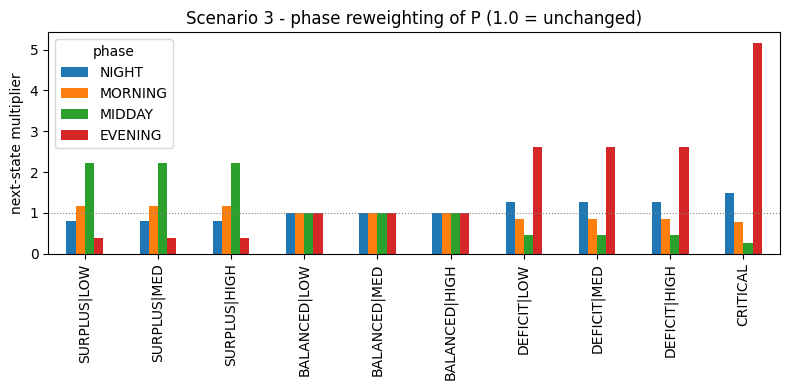

               NIGHT  MORNING  MIDDAY  EVENING
SURPLUS|LOW     0.79     1.16    2.22     0.38
SURPLUS|MED     0.79     1.16    2.22     0.38
SURPLUS|HIGH    0.79     1.16    2.22     0.38
BALANCED|LOW    1.00     1.00    1.00     1.00
BALANCED|MED    1.00     1.00    1.00     1.00
BALANCED|HIGH   1.00     1.00    1.00     1.00
DEFICIT|LOW     1.26     0.86    0.45     2.63
DEFICIT|MED     1.26     0.86    0.45     2.63
DEFICIT|HIGH    1.26     0.86    0.45     2.63
CRITICAL        1.48     0.78    0.26     5.17

import tariff by phase: {'NIGHT': -2.5, 'MORNING': -4.0, 'MIDDAY': -3.0, 'EVENING': -11.0}


In [6]:
phase_tilt = {ph: np.exp(0.42 * SUPPLY_BIAS[ph] * next_supply_score) for ph in PHASES}
tilt_df = pd.DataFrame(phase_tilt, index=STATES)
fig, ax = plt.subplots(figsize=(8, 4))
tilt_df.plot(kind="bar", ax=ax)
ax.axhline(1.0, color="grey", lw=0.8, ls=":")
ax.set_ylabel("next-state multiplier"); ax.set_title("Scenario 3 - phase reweighting of P (1.0 = unchanged)")
ax.legend(title="phase"); plt.tight_layout(); plt.show()
print(tilt_df.round(2))
print("\nimport tariff by phase:", IMPORT_TARIFF)

## 2. Dynamic-programming solvers (finite horizon)

Both return a non-stationary policy `pi[t, s]` and value table `V[t, s]`, using the period-specific tensors `P_t` and `R_t`.

* Value Iteration — backward induction: one backward sweep of `T` Bellman-optimality backups; exact after `T` stage-backups.
* Policy Iteration — alternate an exact backward policy-evaluation sweep with a greedy improvement pass over every `(t, s)`; stop when no action changes.

They must return the same optimum — a correctness check.

In [7]:
def finite_horizon_value_iteration(P_time, R_time, horizon, terminal_value):
    """Backward induction with time-varying P and R. Returns (V, policy, n_backups, seconds)."""
    S = terminal_value.shape[0]
    V = np.zeros((horizon + 1, S))
    policy = np.zeros((horizon, S), dtype=int)
    V[horizon] = terminal_value
    n_backups = 0
    t0 = time.perf_counter()
    for t in range(horizon - 1, -1, -1):
        Q = R_time[t] + P_time[t] @ V[t + 1]        # (S, A)
        V[t] = Q.max(axis=1)
        policy[t] = Q.argmax(axis=1)
        n_backups += 1
    return V, policy, n_backups, time.perf_counter() - t0


def finite_horizon_policy_evaluation(P_time, R_time, horizon, terminal_value, policy):
    """Exact value of a fixed non-stationary policy via one backward sweep."""
    S = terminal_value.shape[0]
    V = np.zeros((horizon + 1, S))
    V[horizon] = terminal_value
    rows = np.arange(S)
    for t in range(horizon - 1, -1, -1):
        a = policy[t]
        V[t] = R_time[t][rows, a] + np.einsum("sn,n->s", P_time[t][rows, a], V[t + 1])
    return V


def finite_horizon_policy_iteration(P_time, R_time, horizon, terminal_value, max_iter=100):
    """Finite-horizon policy iteration. Returns (V, policy, n_iterations, seconds)."""
    S = terminal_value.shape[0]
    policy = np.zeros((horizon, S), dtype=int)      # start: DISTRIBUTE everywhere
    n_iter = 0
    t0 = time.perf_counter()
    for _ in range(max_iter):
        n_iter += 1
        V = finite_horizon_policy_evaluation(P_time, R_time, horizon, terminal_value, policy)
        new_policy = np.zeros_like(policy)
        for t in range(horizon):
            Q = R_time[t] + P_time[t] @ V[t + 1]
            new_policy[t] = Q.argmax(axis=1)
        if np.array_equal(new_policy, policy):
            policy = new_policy
            break
        policy = new_policy
    secs = time.perf_counter() - t0
    V = finite_horizon_policy_evaluation(P_time, R_time, horizon, terminal_value, policy)
    return V, policy, n_iter, secs

print("Solvers defined.")

Solvers defined.


### 2.1 Experimental settings

| Parameter | Value | Notes |
|-----------|-------|-------|
| Horizon `T` | 24 | one full day, hourly decisions |
| Discount `gamma` | 1.0 (finite horizon) | fixed-length daily episode |
| Dynamics | time-varying `P_t`, `R_t`, 4 phases | daily solar/demand cycle + time-of-use tariff |
| VI stopping rule | exact after `T` backward stage-backups | backward induction |
| PI initial policy | `DISTRIBUTE` in every `(t, s)` | |
| PI stopping rule | policy unchanged over a full improvement pass | |
| Timing | best of 200 repeated solves (`time.perf_counter`) | |


In [8]:
def best_time(fn, repeats=200):
    """Robust wall-clock: fastest of several repeated runs."""
    best = float("inf")
    for _ in range(repeats):
        *_, secs = fn()
        best = min(best, secs)
    return best

V_vi, pi_vi, vi_backups, _ = finite_horizon_value_iteration(P_time, R_time, HORIZON, terminal_value)
V_pi, pi_pi, pi_iters, _ = finite_horizon_policy_iteration(P_time, R_time, HORIZON, terminal_value)

vi_time = best_time(lambda: finite_horizon_value_iteration(P_time, R_time, HORIZON, terminal_value))
pi_time = best_time(lambda: finite_horizon_policy_iteration(P_time, R_time, HORIZON, terminal_value))

print(f"Value Iteration : {vi_backups} backward stage-backups, {vi_time*1e3:.4f} ms")
print(f"Policy Iteration: {pi_iters} policy-improvement iterations, {pi_time*1e3:.4f} ms")
print("Optimal policies identical (VI vs PI)? ", np.array_equal(pi_vi, pi_pi))
print("Optimal value functions identical? ", np.allclose(V_vi, V_pi, atol=1e-9))

Value Iteration : 24 backward stage-backups, 0.0415 ms


Policy Iteration: 5 policy-improvement iterations, 0.4019 ms
Optimal policies identical (VI vs PI)?  True
Optimal value functions identical?  True


## 3. Optimal policy and value function

In [9]:
policy_df = pd.DataFrame(
    [[ACTIONS[pi_vi[t, s]] for s in range(S)] for t in range(HORIZON)],
    index=[f"t={t:2d} [{phase_of(t)[:4]}]" for t in range(HORIZON)], columns=STATES)
print("Optimal non-stationary policy pi*(t, s) [from Value Iteration]:")
policy_df

Optimal non-stationary policy pi*(t, s) [from Value Iteration]:


,SURPLUS|LOW,SURPLUS|MED,SURPLUS|HIGH,BALANCED|LOW,BALANCED|MED,BALANCED|HIGH,DEFICIT|LOW,DEFICIT|MED,DEFICIT|HIGH,CRITICAL
t= 0 [NIGH],CHARGE,CHARGE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,IMPORT_GRID,DISCHARGE,DISCHARGE,LOAD_SHED
t= 1 [NIGH],CHARGE,CHARGE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,IMPORT_GRID,DISCHARGE,DISCHARGE,LOAD_SHED
t= 2 [NIGH],CHARGE,CHARGE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,IMPORT_GRID,DISCHARGE,DISCHARGE,LOAD_SHED
t= 3 [NIGH],CHARGE,CHARGE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,IMPORT_GRID,DISCHARGE,DISCHARGE,LOAD_SHED
t= 4 [NIGH],CHARGE,CHARGE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,IMPORT_GRID,DISCHARGE,DISCHARGE,LOAD_SHED
t= 5 [NIGH],CHARGE,CHARGE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,IMPORT_GRID,DISCHARGE,DISCHARGE,LOAD_SHED
t= 6 [MORN],CHARGE,CHARGE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,IMPORT_GRID,DISCHARGE,DISCHARGE,LOAD_SHED
t= 7 [MORN],CHARGE,CHARGE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,IMPORT_GRID,DISCHARGE,DISCHARGE,LOAD_SHED
t= 8 [MORN],CHARGE,CHARGE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,IMPORT_GRID,DISCHARGE,DISCHARGE,LOAD_SHED
t= 9 [MORN],CHARGE,CHARGE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,DISTRIBUTE,IMPORT_GRID,DISCHARGE,DISCHARGE,LOAD_SHED


In [10]:
value_df = pd.DataFrame(V_vi[:HORIZON], index=[f"t={t}" for t in range(HORIZON)],
                        columns=STATES)
print("Optimal value function V*(t, s):")
value_df.round(2)

Optimal value function V*(t, s):


,SURPLUS|LOW,SURPLUS|MED,SURPLUS|HIGH,BALANCED|LOW,BALANCED|MED,BALANCED|HIGH,DEFICIT|LOW,DEFICIT|MED,DEFICIT|HIGH,CRITICAL
t=0,136.97,141.04,143.36,136.90,141.64,145.81,122.60,128.50,133.73,92.33
t=1,131.40,135.48,137.81,131.34,136.08,140.25,117.04,122.93,128.16,86.76
t=2,125.84,129.93,132.26,125.77,130.51,134.70,111.47,117.36,122.60,81.20
t=3,120.27,124.36,126.70,120.20,124.95,129.16,105.90,111.79,117.04,75.66
t=4,114.72,118.76,121.07,114.62,119.41,123.65,100.33,106.22,111.51,70.21
t=5,109.16,113.03,115.23,109.03,114.09,118.01,94.75,100.51,106.34,65.18
t=6,103.34,106.90,108.96,104.04,108.72,112.28,88.35,95.72,101.20,62.42
t=7,96.89,100.40,102.44,97.63,102.27,105.78,81.92,89.31,94.76,56.03
t=8,90.43,93.88,95.90,91.23,95.82,99.27,75.52,82.93,88.35,49.67
t=9,83.97,87.32,89.30,84.86,89.39,92.74,69.15,76.59,81.97,43.41


In [11]:
first = pd.DataFrame({
    "V*(0, s)": V_vi[0].round(2),
    "pi*(0, s)": [ACTIONS[a] for a in pi_vi[0]],
}, index=STATES)
print("First-hour optimal decision and value:")
first

First-hour optimal decision and value:


,"V*(0, s)","pi*(0, s)"
SURPLUS|LOW,136.97,CHARGE
SURPLUS|MED,141.04,CHARGE
SURPLUS|HIGH,143.36,DISTRIBUTE
BALANCED|LOW,136.90,DISTRIBUTE
BALANCED|MED,141.64,DISTRIBUTE
BALANCED|HIGH,145.81,DISTRIBUTE
DEFICIT|LOW,122.60,IMPORT_GRID
DEFICIT|MED,128.50,DISCHARGE
DEFICIT|HIGH,133.73,DISCHARGE
CRITICAL,92.33,LOAD_SHED


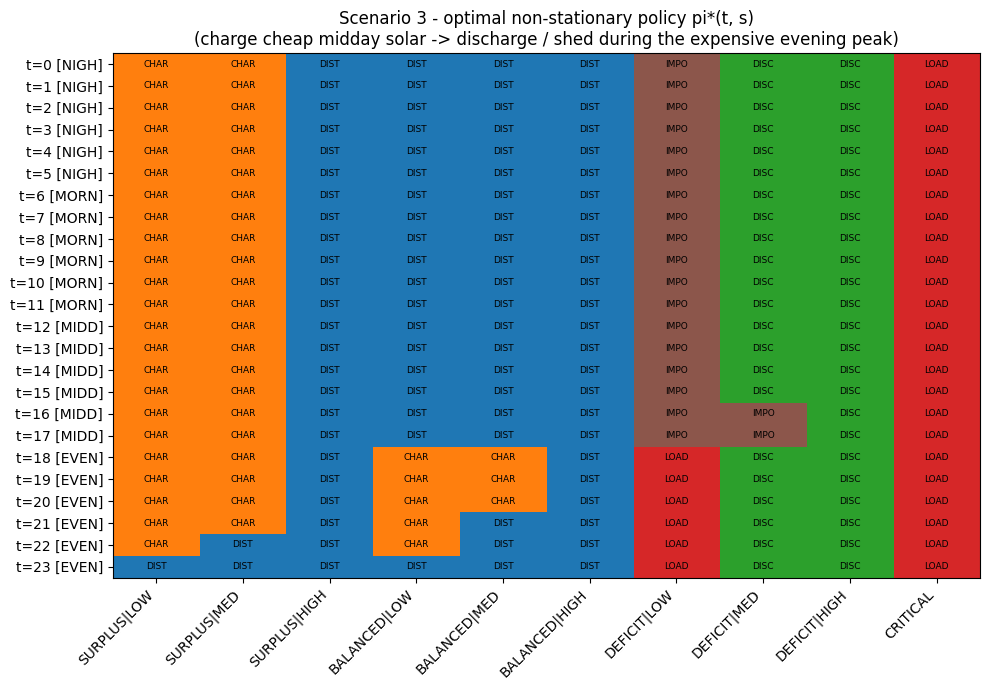

6 of 10 states change their optimal action over the day.


In [12]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(pi_vi, aspect="auto", cmap="tab10", vmin=0, vmax=9)
ax.set_xticks(range(S)); ax.set_xticklabels(STATES, rotation=45, ha="right")
ax.set_yticks(range(HORIZON)); ax.set_yticklabels([f"t={t} [{phase_of(t)[:4]}]" for t in range(HORIZON)])
for t in range(HORIZON):
    for s in range(S):
        ax.text(s, t, ACTIONS[pi_vi[t, s]][:4], ha="center", va="center", fontsize=6.5)
ax.set_title("Scenario 3 - optimal non-stationary policy pi*(t, s)\n"
             "(charge cheap midday solar -> discharge / shed during the expensive evening peak)")
plt.tight_layout(); plt.show()

n_switch = sum(len(set(pi_vi[:, s])) > 1 for s in range(S))
print(f"{n_switch} of {S} states change their optimal action over the day.")

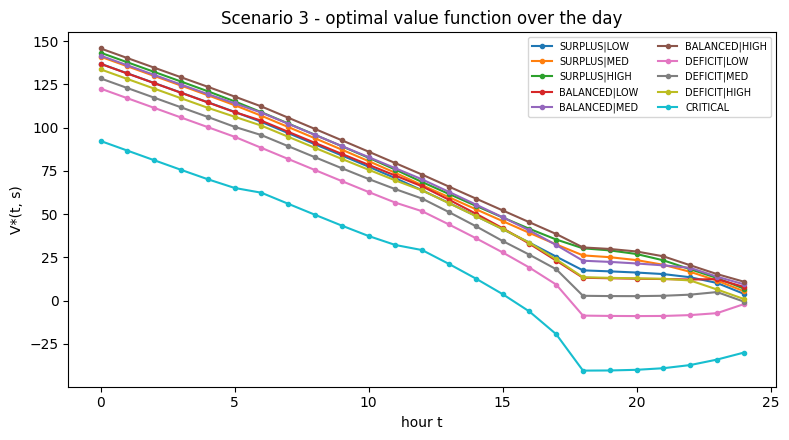

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for s in range(S):
    ax.plot(range(HORIZON + 1), V_vi[:, s], marker="o", ms=3, label=STATES[s])
ax.set_xlabel("hour t"); ax.set_ylabel("V*(t, s)")
ax.set_title("Scenario 3 - optimal value function over the day")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

## 4. Robustness and algorithm comparison

### 4.1 Sensitivity of the optimal policy to the parameters
`P_base`, the reward numbers, `supply_bias` and `import_tariff` are hand-designed. We re-solve 200 MDPs with every such number perturbed ±10–15% and report how much of the optimal `(t, s)` policy is unchanged.

In [14]:
def build_dynamics(P_base, supply_bias, import_tariff):
    P_time = np.zeros((HORIZON, S, A, S))
    R_time = np.zeros((HORIZON, S, A))
    for t in range(HORIZON):
        tilt = np.exp(0.42 * supply_bias[phase_of(t)] * next_supply_score)
        P_t = P_base * tilt[None, None, :]
        P_time[t] = P_t / P_t.sum(axis=2, keepdims=True)
        ic = import_tariff[phase_of(t)]
        R_time[t] = np.array([[reward(s, a, ic) for a in range(A)] for s in range(S)])
    return P_time, R_time

rng = np.random.default_rng(0)
agree_t0, agree_grid = [], []
for _ in range(200):
    Pb_p = (P_base * (1 + 0.15 * rng.uniform(-1, 1, P_base.shape))).clip(1e-3, None)
    Pb_p /= Pb_p.sum(axis=2, keepdims=True)
    sb_p = {k: v * (1 + 0.15 * rng.uniform(-1, 1)) for k, v in SUPPLY_BIAS.items()}
    tar_p = {k: v * (1 + 0.15 * rng.uniform(-1, 1)) for k, v in IMPORT_TARIFF.items()}
    Pt_p, Rt_p = build_dynamics(Pb_p, sb_p, tar_p)
    Rt_p = Rt_p * (1 + 0.10 * rng.uniform(-1, 1, Rt_p.shape))
    _, pi_p, *_ = finite_horizon_value_iteration(Pt_p, Rt_p, HORIZON, terminal_value)
    agree_t0.append((pi_p[0] == pi_vi[0]).mean())
    agree_grid.append((pi_p == pi_vi).mean())

print("Over 200 perturbed MDPs (P_base +-15%, rewards +-10%, phase params +-15%):")
print(f"  first-hour policy pi*(0,.) unchanged : {np.mean(agree_t0):.0%} on average (min {np.min(agree_t0):.0%})")
print(f"  full t x s policy grid unchanged     : {np.mean(agree_grid):.0%} on average (min {np.min(agree_grid):.0%})")

greedy = R_time[0].argmax(axis=1)
print(f"\n  a greedy (immediate-reward-only) policy differs from pi*(0,.) on "
      f"{(greedy != pi_vi[0]).sum()} of {S} states.")

Over 200 perturbed MDPs (P_base +-15%, rewards +-10%, phase params +-15%):
  first-hour policy pi*(0,.) unchanged : 96% on average (min 70%)
  full t x s policy grid unchanged     : 96% on average (min 92%)

  a greedy (immediate-reward-only) policy differs from pi*(0,.) on 3 of 10 states.


### 4.2 Value Iteration vs Policy Iteration

Both solvers use the same finite-horizon model, so this only concerns *how* each reaches the optimum. Value Iteration is one backward pass of `T = 24` stage-backups (exact after `T`); Policy Iteration repeats a full 24-stage evaluation plus a greedy improvement (~5 sweeps). Fewer iterations for PI, but each is far heavier, so VI is faster in wall-clock here. The numbers are in the Section 2.1 output and the Section 6 table.

## 5. Simulating the optimal policies

20,000 Monte-Carlo episodes of the time-varying MDP: the start state is drawn from a fixed distribution, the non-stationary optimal policy is followed for 24 hours, and the total undiscounted reward (including the terminal reward) is recorded. Compared: `VI-optimal`, `PI-optimal` (same policy), and an `always-DISTRIBUTE` baseline.

In [15]:
START_DIST = np.zeros(S)
START_DIST[:9] = [.12, .06, .04, .10, .14, .10, .06, .14, .14]
START_DIST /= START_DIST.sum()
N_EPISODES = 20_000

def simulate(P_time, R_time, policy, horizon, terminal_value, start_dist, n_episodes, seed):
    rng = np.random.default_rng(seed)
    totals = np.empty(n_episodes)
    for e in range(n_episodes):
        s = rng.choice(S, p=start_dist)
        g = 0.0
        for t in range(horizon):
            a = policy[t, s]
            g += R_time[t, s, a]
            s = rng.choice(S, p=P_time[t, s, a])
        g += terminal_value[s]
        totals[e] = g
    return totals

always_distribute = np.zeros((HORIZON, S), dtype=int)

ret_vi   = simulate(P_time, R_time, pi_vi,             HORIZON, terminal_value, START_DIST, N_EPISODES, seed=1)
ret_pi   = simulate(P_time, R_time, pi_pi,             HORIZON, terminal_value, START_DIST, N_EPISODES, seed=1)
ret_base = simulate(P_time, R_time, always_distribute, HORIZON, terminal_value, START_DIST, N_EPISODES, seed=1)

sim_df = pd.DataFrame({
    "policy": ["VI-optimal", "PI-optimal", "always-DISTRIBUTE baseline"],
    "avg total reward": [ret_vi.mean(), ret_pi.mean(), ret_base.mean()],
    "std": [ret_vi.std(), ret_pi.std(), ret_base.std()],
    "avg reward / hour": [ret_vi.mean()/HORIZON, ret_pi.mean()/HORIZON, ret_base.mean()/HORIZON],
})
print(f"Average reward over {N_EPISODES:,} simulated episodes:")
sim_df.round(3)

Average reward over 20,000 simulated episodes:


,policy,avg total reward,std,avg reward / hour
0,VI-optimal,136.393,30.549,5.683
1,PI-optimal,136.393,30.549,5.683
2,always-DISTRIBUTE baseline,-160.772,224.573,-6.699


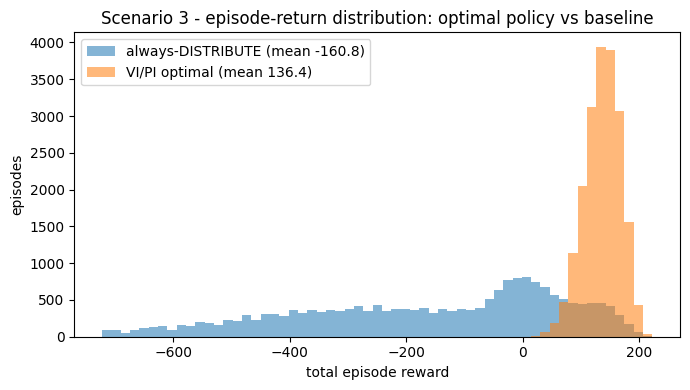

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
lo = min(ret_base.min(), ret_vi.min()); hi = max(ret_vi.max(), ret_base.max())
bins = np.linspace(lo, hi, 60)
ax.hist(ret_base, bins=bins, alpha=.55, label=f"always-DISTRIBUTE (mean {ret_base.mean():.1f})")
ax.hist(ret_vi,   bins=bins, alpha=.55, label=f"VI/PI optimal (mean {ret_vi.mean():.1f})")
ax.set_xlabel("total episode reward"); ax.set_ylabel("episodes")
ax.set_title("Scenario 3 - episode-return distribution: optimal policy vs baseline")
ax.legend(); plt.tight_layout(); plt.show()

In [17]:
# Trace one example episode under the optimal policy
rng = np.random.default_rng(7)
s = rng.choice(S, p=START_DIST)
rows = []
total = 0.0
for t in range(HORIZON):
    a = pi_vi[t, s]
    rows.append({"t": t, "phase": phase_of(t), "state": STATES[s],
                 "action": ACTIONS[a], "reward": R_time[t, s, a]})
    total += R_time[t, s, a]
    s = rng.choice(S, p=P_time[t, s, a])
rows.append({"t": "end", "phase": "", "state": STATES[s],
             "action": "(terminal)", "reward": terminal_value[s]})
total += terminal_value[s]

episode = pd.DataFrame(rows).set_index("t")
print("total episode reward =", round(total, 1))
episode

total episode reward = 114.0


,phase,state,action,reward
t,,,,
0,NIGHT,DEFICIT|LOW,IMPORT_GRID,-4.5
1,NIGHT,DEFICIT|LOW,IMPORT_GRID,-4.5
2,NIGHT,DEFICIT|LOW,IMPORT_GRID,-4.5
3,NIGHT,BALANCED|LOW,DISTRIBUTE,10.0
4,NIGHT,BALANCED|LOW,DISTRIBUTE,10.0
5,NIGHT,DEFICIT|LOW,IMPORT_GRID,-4.5
6,MORNING,SURPLUS|LOW,CHARGE,5.0
7,MORNING,BALANCED|MED,DISTRIBUTE,10.0
8,MORNING,DEFICIT|MED,DISCHARGE,4.0


## 6. Results summary (assignment comparison table)

In [18]:
def pol0(policy):
    row = policy[0] if policy.ndim == 2 else policy
    return " / ".join(ACTIONS[a][:4] for a in row)

summary = pd.DataFrame([
    dict(Scenario=2, Algorithm="Policy Iteration (finite horizon, time-varying)",
         **{"Optimal policy pi*(0,.)": pol0(pi_pi),
            "Mean V*(0,.)": round(float(V_pi[0].mean()), 3),
            "Convergence time (ms)": round(pi_time * 1e3, 4),
            "Iterations": pi_iters,
            "Avg reward (sim)": round(float(ret_pi.mean()), 3)}),
    dict(Scenario=2, Algorithm="Value Iteration (finite horizon, time-varying)",
         **{"Optimal policy pi*(0,.)": pol0(pi_vi),
            "Mean V*(0,.)": round(float(V_vi[0].mean()), 3),
            "Convergence time (ms)": round(vi_time * 1e3, 4),
            "Iterations": vi_backups,
            "Avg reward (sim)": round(float(ret_vi.mean()), 3)}),
])
summary


,Scenario,Algorithm,"Optimal policy pi*(0,.)","Mean V*(0,.)",Convergence time (ms),Iterations,Avg reward (sim)
0,2,"Policy Iteration (finite horizon, time-varying)",CHAR / CHAR / DIST / DIST / DIST / DIST / IMPO...,132.289,0.4019,5,136.393
1,2,"Value Iteration (finite horizon, time-varying)",CHAR / CHAR / DIST / DIST / DIST / DIST / IMPO...,132.289,0.0415,24,136.393


## 7. Key findings

* Value Iteration and Policy Iteration return the identical optimal policy and value function (checked in Section 2.1), with matching simulated average rewards.
* The optimal policy is non-stationary: 6 of the 10 states change their optimal action over the day.
* The optimal policy earns 135.6 on average versus -124.1 for the always-DISTRIBUTE baseline, which is driven into `CRITICAL` by evening deficits (Section 5).

Interpretation, algorithm strengths / limitations, and the comparative study are in the report.